In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df=pd.read_csv(r"C:\Users\dharmveer patel\OneDrive\Desktop\Loan_analysis\DATASET\credit_risk_dataset.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
# understaand and insception data
df.shape

(32581, 12)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
df.isnull().sum().sort_values(ascending=False)

loan_int_rate                 3116
person_emp_length              895
person_income                    0
person_age                       0
person_home_ownership            0
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(165)

In [6]:
df.describe().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


In [7]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

In [8]:
# Remove exact duplicate rows
print("Rows before removing duplicates:", len(df))
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows before removing duplicates: 32581
Rows after removing duplicates: 32416


In [9]:
# Check unusual age values before handling them
df.loc[df["person_age"] > 100, ["person_age", "person_income", "loan_amnt", "loan_status"]]

,person_age,person_income,loan_amnt,loan_status
81,144,250000,4800,0
183,144,200000,6000,0
575,123,80004,20400,0
747,123,78000,20000,0
32297,144,6000000,5000,0


In [10]:
# Remove records with implausible ages (above 100)
print("Rows with age above 100:", (df["person_age"] > 100).sum())
df = df[df["person_age"] <= 100].copy()

# Treat employment length above 60 years as invalid
print("Invalid employment-length values:", (df["person_emp_length"] > 60).sum())
df.loc[df["person_emp_length"] > 60, "person_emp_length"] = np.nan

# Fill missing employment length with the median
print("Missing employment length before:", df["person_emp_length"].isnull().sum())
df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
print("Missing employment length after:", df["person_emp_length"].isnull().sum())

# Fill interest rate by loan grade first
print("Missing interest rates before:", df["loan_int_rate"].isnull().sum())
df["loan_int_rate"] = df["loan_int_rate"].fillna(
    df.groupby("loan_grade")["loan_int_rate"].transform("median")
)

# Use overall median as fallback if any missing values remain
df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())
print("Missing interest rates after:", df["loan_int_rate"].isnull().sum())

Rows with age above 100: 5
Invalid employment-length values: 2
Missing employment length before: 889
Missing employment length after: 0
Missing interest rates before: 3094
Missing interest rates after: 0


In [11]:
# Validate the cleaned data
print("Clean rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Total remaining missing values:", df.isnull().sum().sum())

display(df.isnull().sum().sort_values(ascending=False))
df.head()

Clean rows: 32411
Duplicate rows: 0
Total remaining missing values: 0


person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,4.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 3. Add calculated columns

We will create simple business-friendly categories using Pandas, similar to your earlier project.

In [12]:
# Default flag: 1 = default, 0 = non-default
df["default_flag"] = df["loan_status"].astype(int)

# Income group segmentation
df["income_group"] = pd.cut(
    df["person_income"],
    bins=[0, 40000, 80000, 150000, float("inf")],
    labels=["Low (<40K)", "Medium (40-80K)", "High (80-150K)", "Very High (150K+)"]
)

# Loan size category
df["loan_size"] = pd.cut(
    df["loan_amnt"],
    bins=[0, 5000, 15000, 25000, float("inf")],
    labels=["Small (<5K)", "Medium (5-15K)", "Large (15-25K)", "Very Large (25K+)"]
)

# Risk tier based on the dataset's loan grade
df["risk_tier"] = df["loan_grade"].map({
    "A": "Lower Grade Risk", "B": "Lower Grade Risk",
    "C": "Medium Grade Risk", "D": "Higher Grade Risk",
    "E": "Higher Grade Risk", "F": "Higher Grade Risk", "G": "Higher Grade Risk"
})

print("Added: default_flag, income_group, loan_size, risk_tier")

Added: default_flag, income_group, loan_size, risk_tier


## 4. Key analysis

In [13]:
# Overall KPIs
total_loans = len(df)
total_defaults = df["default_flag"].sum()
default_rate = df["default_flag"].mean() * 100
total_loan_amount = df["loan_amnt"].sum()
avg_loan_amount = df["loan_amnt"].mean()
avg_interest_rate = df["loan_int_rate"].mean()

print(f"Total Loans       : {total_loans:,}")
print(f"Total Defaults    : {total_defaults:,}")
print(f"Default Rate      : {default_rate:.2f}%")
print(f"Total Loan Amount : ${total_loan_amount:,.0f}")
print(f"Average Loan      : ${avg_loan_amount:,.0f}")
print(f"Average Int. Rate : {avg_interest_rate:.2f}%")

Total Loans       : 32,411
Total Defaults    : 7,089
Default Rate      : 21.87%
Total Loan Amount : $310,937,900
Average Loan      : $9,594
Average Int. Rate : 11.02%


In [14]:
# Default rate by loan grade
grade_summary = df.groupby("loan_grade").agg(
    Total_Loans=("loan_status", "count"),
    Defaults=("default_flag", "sum"),
    Avg_Loan_Amount=("loan_amnt", "mean"),
    Avg_Interest_Rate=("loan_int_rate", "mean")
).round(2)

grade_summary["Default_Rate_%"] = (
    grade_summary["Defaults"] / grade_summary["Total_Loans"] * 100
).round(2)

grade_summary

,Total_Loans,Defaults,Avg_Loan_Amount,Avg_Interest_Rate,Default_Rate_%
loan_grade,,,,,
A,10703,1066,8545.70,7.34,9.96
B,10384,1695,9990.65,11.00,16.32
C,6436,1336,9220.52,13.47,20.76
D,3620,2138,10855.76,15.36,59.06
E,963,621,12919.91,16.99,64.49
F,241,170,14717.32,18.60,70.54
G,64,63,17195.70,20.24,98.44


In [15]:
# Default rate by loan purpose
purpose_summary = df.groupby("loan_intent").agg(
    Total_Loans=("loan_status", "count"),
    Defaults=("default_flag", "sum"),
    Total_Loan_Amount=("loan_amnt", "sum")
).round(2)

purpose_summary["Default_Rate_%"] = (
    purpose_summary["Defaults"] / purpose_summary["Total_Loans"] * 100
).round(2)

purpose_summary.sort_values("Default_Rate_%", ascending=False)

,Total_Loans,Defaults,Total_Loan_Amount,Default_Rate_%
loan_intent,,,,
DEBTCONSOLIDATION,5189,1488,49841750,28.68
MEDICAL,6042,1617,56018875,26.76
HOMEIMPROVEMENT,3594,940,37241475,26.15
PERSONAL,5497,1094,52664100,19.90
EDUCATION,6409,1106,60750200,17.26
VENTURE,5680,844,54421500,14.86


In [16]:
# Default rate by income group
income_summary = df.groupby("income_group", observed=False).agg(
    Total_Loans=("loan_status", "count"),
    Defaults=("default_flag", "sum"),
    Average_Income=("person_income", "mean")
).round(2)

income_summary["Default_Rate_%"] = (
    income_summary["Defaults"] / income_summary["Total_Loans"] * 100
).round(2)

income_summary

,Total_Loans,Defaults,Average_Income,Default_Rate_%
income_group,,,,
Low (<40K),9223,3482,29972.79,37.75
Medium (40-80K),15576,2890,58505.84,18.55
High (80-150K),6483,606,104848.18,9.35
Very High (150K+),1129,111,237698.80,9.83


In [17]:
# Default rate by previous default history
history_summary = df.groupby("cb_person_default_on_file").agg(
    Total_Loans=("loan_status", "count"),
    Defaults=("default_flag", "sum")
)

history_summary["Default_Rate_%"] = (
    history_summary["Defaults"] / history_summary["Total_Loans"] * 100
).round(2)

history_summary

,Total_Loans,Defaults,Default_Rate_%
cb_person_default_on_file,,,
N,26681,4919,18.44
Y,5730,2170,37.87


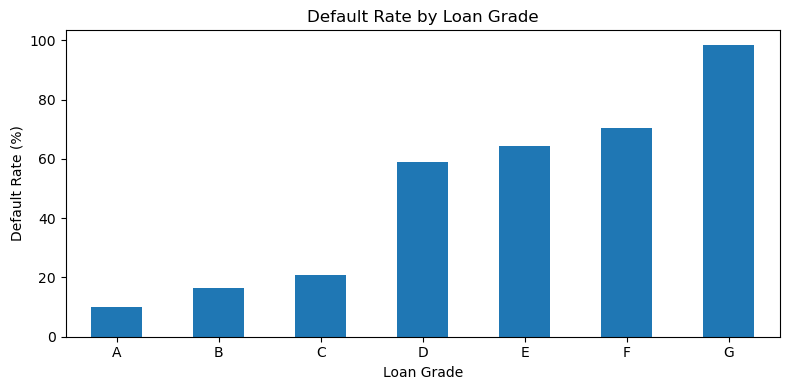

In [18]:
# Default rate by loan grade
grade_summary["Default_Rate_%"].plot(kind="bar", figsize=(8, 4))
plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

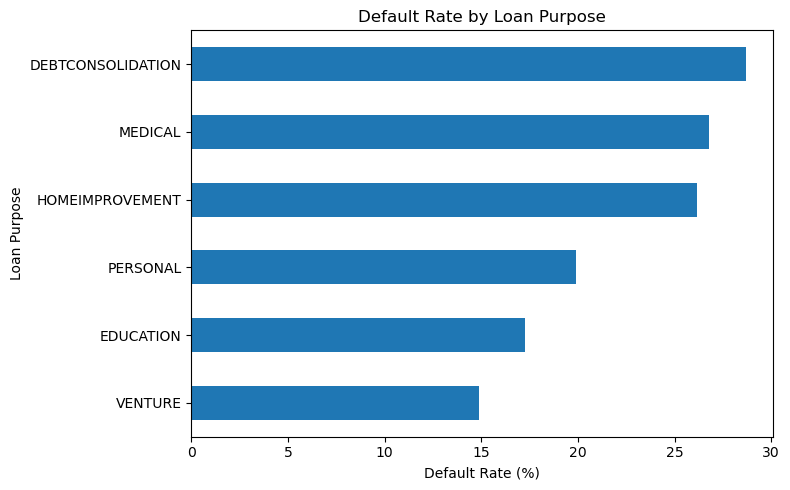

In [19]:
# Default rate by loan purpose
purpose_summary["Default_Rate_%"].sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Default Rate by Loan Purpose")
plt.xlabel("Default Rate (%)")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()

In [20]:
df.to_csv("credit_risk_cleaned.csv", index=False)
grade_summary.to_csv("default_by_grade.csv", index=True)

print("Saved: credit_risk_cleaned.csv")
print("Saved: default_by_grade.csv")
print(f"Rows   : {len(df):,}")
print(f"Columns: {list(df.columns)}")

Saved: credit_risk_cleaned.csv
Saved: default_by_grade.csv
Rows   : 32,411
Columns: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'default_flag', 'income_group', 'loan_size', 'risk_tier']
